# Find regulons and co-regulated gene programs

A **regulon** is a transcription factor together with the genes it is predicted to regulate.
SCENIC finds regulons in RNA data in two steps. Genes whose expression follows a factor's
expression become candidate targets, and motif enrichment near those genes keeps the targets
that the factor can plausibly bind. Chromatin accessibility adds independent evidence: when
peaks that hold a factor's motif, or peaks that a CUT&RUN experiment saw the factor bind, are
more accessible in some cells than expected, the factor is likely active there.

This tutorial uses one 10x Genomics multiome sample of about 2,700 peripheral blood
mononuclear cells (PBMCs), with RNA and ATAC measured in the same cells. We will:

1. infer RNA regulons with the SCENIC workflow;
2. find gene programs, groups of genes that vary together as a unit, from RNA alone;
3. score motif accessibility in the same cells with chromVAR;
4. score the binding sites of a CUT&RUN experiment;
5. combine both modalities into enhancer-driven regulons, as SCENIC+ does.

The first cell downloads about 1.3 GB of public files: the 10x data (CC BY 4.0), a cisTarget
motif-ranking database and motif annotations from the Aerts lab, JASPAR 2024 motifs
(CC BY 4.0), the GENCODE v32 genome and gene annotation, and SPI1 CUT&RUN peaks from
ChIP-Atlas (CC BY-SA 4.0). Reading the motif-ranking database needs the `regulons` extra:
`pip install "cytearc[extra,regulons]"`.

In [1]:
# Import tools for downloading and decompressing the reference files.
import gzip
import shutil
from pathlib import Path
from urllib.request import Request, urlopen

# Import plotting and table tools for inspecting the results.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Import CyteArc's datastore and regulon methods.
import cytearc
from cytearc import regulons as rg

# Keep warnings visible while hiding routine progress messages.
cytearc.configure_output(level="WARNING", progress=False)

# Show whole gene lists in tables.
pd.set_option("display.max_colwidth", 120)

# Keep the downloaded reference files in one folder.
inputs = Path("regulon_inputs")

# Create the folder on the first run.
inputs.mkdir(exist_ok=True)


# Download a file once and return its local path.
def fetch(url):

    # Name the local copy after the last part of the URL.
    path = inputs / url.rsplit("/", 1)[1]

    # Reuse the copy from an earlier run.
    if path.exists():
        return path

    # Name the client, because some hosts refuse Python's default one.
    request = Request(url, headers={"User-Agent": "CyteArc documentation"})

    # Write to a temporary name, so that an interrupted download is never reused.
    partial = path.with_name(path.name + ".part")
    with urlopen(request) as response, open(partial, "wb") as target:
        shutil.copyfileobj(response, target)

    # Give the complete file its final name.
    return partial.rename(path)


# Download the 10x Genomics PBMC multiome sample (Cell Ranger ARC 2.0, GRCh38).
matrix_h5 = fetch(
    "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_3k/"
    "pbmc_granulocyte_sorted_3k_filtered_feature_bc_matrix.h5"
)

# Download the human transcription factors that the motif annotations cover.
tf_list = fetch("https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt")

# Download the cisTarget database, which ranks every gene by each motif's best match near it.
ranking_db = fetch(
    "https://resources.aertslab.org/cistarget/databases/homo_sapiens/hg38/refseq_r80/mc_v10_clust/"
    "gene_based/hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather"
)

# Download the table that assigns each cisTarget motif to transcription factors.
motif_table = fetch(
    "https://resources.aertslab.org/cistarget/motif2tf/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl"
)

# Download the JASPAR 2024 vertebrate motifs.
jaspar = fetch(
    "https://jaspar.elixir.no/download/data/2024/CORE/"
    "JASPAR2024_CORE_vertebrates_non-redundant_pfms_jaspar.txt"
)

# Use the GENCODE release that the 10x peaks were called against.
gencode = "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/"

# Download the genome sequence.
genome_gz = fetch(gencode + "GRCh38.primary_assembly.genome.fa.gz")

# Download the gene annotation.
gene_gtf = fetch(gencode + "gencode.v32.primary_assembly.annotation.gtf.gz")

# Download SPI1 (PU.1) CUT&RUN peaks from primary human monocytes (GEO GSM8669389).
spi1_cutrun = fetch("https://chip-atlas.dbcls.jp/data/hg38/eachData/bed05/SRX26995709.05.bed")

# Name the decompressed genome, which motif scanning reads at many positions.
genome_fa = inputs / "GRCh38.primary_assembly.genome.fa"

# Decompress the genome once.
if not genome_fa.exists():
    with gzip.open(genome_gz, "rb") as source, open(genome_fa, "wb") as target:
        shutil.copyfileobj(source, target)

Started: 2026-10-16T08:41:51.116746Z | Wall time: 1941.605 s

## Build the store and name the populations

Convert the 10x matrix into a CyteArc store. Its RNA and ATAC peak counts become two assays
over the same cells. The standard RNA pipeline then selects cells and genes, builds the
neighbor graph and UMAP, and clusters the cells.

In [2]:
# Write both assays of the 10x matrix into one store.
cytearc.CrToZarr(cytearc.CrH5Reader(str(matrix_h5)), zarr_loc="pbmc_multiome.zarr").dump()

# Open the store for writing; the pipeline below decides which cells pass quality control.
ds = cytearc.DataStore(
    "pbmc_multiome.zarr",
    default_assay="RNA",
    min_features_per_cell=-1,
    nthreads=4,
)

# Run the standard RNA recipe: cell and gene selection, graph, UMAP, and clusters.
run = ds.pipeline.run(label="baseline")

# Keep the cells that the pipeline analysed.
cells = run["analysis_cell_selection"]

# Mark the analysed cells among all cells of the store.
analysed = np.asarray(run.cells.fetch_all("I"), dtype=bool)

# Inspect the store's assays and their dimensions.
ds

DataStore has 2711 (2711) cells with 2 assays: ATAC RNA
   Cell metadata:
            'I', 'ids', 'names', 'ATAC_nCounts', 'ATAC_nFeatures', 
            'RNA_nCounts', 'RNA_nFeatures', 'RNA_percentMito', 'RNA_percentRibo'
   ATAC assay has 98319 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'interval', 'nCells'
   RNA assay has 36601 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'genome', 'interval', 'nCells'

Started: 2026-10-16T09:14:12.728378Z | Wall time: 100.740 s

Name the clusters with a small panel of canonical markers. Each cluster takes the panel whose
mean expression, scaled across clusters, is highest. These names make the results easier to
read; they are not a substitute for the annotation workflow in [](annotation.ipynb).

In [3]:
# Define canonical PBMC marker panels.
panels = {
    "CD14 monocyte": ["CD14", "LYZ", "VCAN", "S100A8"],
    "CD16 monocyte": ["FCGR3A", "MS4A7", "LST1"],
    "Dendritic cell": ["FCER1A", "CD1C", "CLEC10A"],
    "Plasmacytoid DC": ["LILRA4", "IL3RA", "CLEC4C"],
    "B cell": ["MS4A1", "CD79A", "BANK1", "PAX5"],
    "CD4 T cell": ["CD3E", "IL7R", "CD4"],
    "CD8 T cell": ["CD3E", "CD8A", "CD8B"],
    "NK cell": ["NKG7", "GNLY", "KLRD1"],
}

# Average the normalized expression of every gene within each cluster.
means = ds.compare.compute_bulk(run["clusters"], feature_label="name")

# Drop gene names that several features share, so that each name selects one row.
means = means.loc[~means.index.duplicated(keep=False)]

# Scale each gene across clusters; a gene that is constant across clusters stays at zero.
scaled = means.sub(means.mean(axis=1), axis=0).div(means.std(axis=1).replace(0, 1), axis=0)

# Score every panel in every cluster as the mean scaled expression of its genes.
panel_scores = pd.DataFrame({name: scaled.loc[genes].mean() for name, genes in panels.items()})

# Name each cluster after its best-scoring panel.
cluster_names = panel_scores.idxmax(axis=1)

# Name each analysed cell after its cluster.
cell_type = cluster_names.reindex(run.cells.fetch("clusters").astype(str)).to_numpy()

# Count the analysed cells of each population.
pd.Series(cell_type).value_counts()

CD4 T cell         858
CD14 monocyte      719
CD8 T cell         525
B cell             192
CD16 monocyte      121
NK cell            102
Dendritic cell      66
Plasmacytoid DC     29
Name: count, dtype: int64

Started: 2026-10-16T09:15:53.471245Z | Wall time: 0.829 s

## Infer RNA regulons

GRNBoost2 asks, for every gene, how well each transcription factor's expression predicts it,
using gradient-boosted trees on raw counts. `ds.regulons.grn` runs it with the pySCENIC
settings and saves the network as an artifact. It is the slowest step, so this page fits it
on 500 sampled cells, the highly variable genes, and every transcription factor detected in
at least 1% of cells. Use all cells and expressed genes in a real analysis.

In [4]:
# Start a random generator with a fixed seed, so that the sample is reproducible.
rng = np.random.default_rng(0)

# Mark 500 analysed cells, drawn at random, for network inference.
sample = np.zeros(ds.cells.N, dtype=bool)
sample[rng.choice(np.flatnonzero(analysed), size=500, replace=False)] = True

# Save the sample as a cell column.
ds.cells.insert("grn_cells", sample, overwrite=True)

# Freeze the sample as the cells that the network models.
grn_cells = ds.snapshot_cell_selection("grn_cells")

# Read the human transcription factors that the motif annotations cover.
tfs = tf_list.read_text().split()

# Read the gene name of every RNA feature.
names = np.asarray(ds.RNA.feats.fetch_all("names")).astype(str)

# Mark the highly variable genes that the pipeline selected.
variable = np.asarray(run.features.fetch_all("highly_variable_features"), dtype=bool)

# Find the genes detected in at least 1% of analysed cells.
detected = ds.features.detected(cells, min_cells=int(analysed.sum() // 100))

# Mark those genes.
expressed = np.asarray(ds.artifacts.load(detected)["values"][:], dtype=bool)

# Model the highly variable genes and every detected transcription factor.
grn_genes = ds.features.snapshot(
    from_assay="RNA",
    mask=variable | (expressed & np.isin(names, tfs)),
)

# Score every factor-to-gene link with GRNBoost2.
grn = ds.regulons.grn(grn_cells, features=grn_genes, tfs=tfs, random_seed=777)

# Load the links with their importance and correlation.
adjacencies = ds.regulons.load_grn(grn).adjacencies

# Inspect the strongest links.
adjacencies.head()

,TF,target,importance,correlation
0,IRF7,CLEC4C,76.803128,0.864336
1,IRF7,LINC01478,76.534487,0.736089
2,IRF7,PTPRS,71.807399,0.713395
3,IRF7,RHEX,71.732840,0.746469
4,IRF7,TCF4,68.916118,0.801061


Started: 2026-10-16T09:15:54.303503Z | Wall time: 225.439 s

Each row is a link from a factor to a target gene. `importance` measures how much the factor
helps predict the gene, and `correlation` gives the direction. pySCENIC turns each factor's
strongest activating links into several candidate modules, then keeps only the targets that a
motif annotated to that factor ranks highly. The database ranks every gene by the best match
of each motif from 10 kb upstream of its transcription start site to 10 kb past its end.

In [5]:
# Build pySCENIC's candidate modules from the activating links.
modules = rg.modules_from_adjacencies(adjacencies)

# Open the motif-ranking database.
database = rg.RankingDatabase(ranking_db)

# Read the transcription factors that each motif is annotated to.
annotations = rg.read_motif_annotations(motif_table)

# Keep the module targets that an enriched motif of the module's factor recovers.
enriched = rg.prune_modules(modules, [database], annotations, nthreads=4)

# Merge every factor's surviving targets into one regulon.
regulons = rg.regulons_from_motifs(enriched)

# List the ten largest regulons.
regulons.groupby("source").size().nlargest(10)

source
KLF4(+)     212
BACH1(+)    209
KLF6(+)     198
SPI1(+)     177
FOXN2(+)    120
CHD1(+)     118
KLF12(+)    110
BCL6(+)     104
NR3C1(+)    103
IKZF1(+)    101
dtype: int64

Started: 2026-10-16T09:19:39.744849Z | Wall time: 18.689 s

Score every regulon in every analysed cell with AUCell. A cell scores high when the regulon's
genes are among its most strongly expressed genes. The regulon specificity score (RSS) then
measures how concentrated each regulon's activity is in each population; 1 means the regulon
is active only, and evenly, in that population.

In [6]:
# Score the regulons with at least ten genes in every analysed cell.
regulon_auc = ds.scores.aucell(regulons, cells, features=run["feature_universe"], tmin=10)

# Read the scores as a cells-by-regulons table.
activity = ds.scores.load(regulon_auc).to_pandas()

# Score how specific each regulon's activity is to each population.
rss = rg.regulon_specificity(activity, cell_type)

# List the three most specific regulons of each population.
rss.apply(lambda scores: ", ".join(scores.nlargest(3).index), axis=1).to_frame("most specific regulons")

,most specific regulons
group,
NK cell,"TBX21(+), EOMES(+), IKZF2(+)"
CD14 monocyte,"ATF3(+), STAT2(+), CEBPD(+)"
B cell,"EBF1(+), PATZ1(+), TCF4(+)"
CD8 T cell,"EOMES(+), TBX21(+), ETS1(+)"
CD4 T cell,"ETS1(+), NFATC2(+), BACH2(+)"
CD16 monocyte,"BATF3(+), CEBPB(+), CEBPA(+)"
Plasmacytoid DC,"RUNX2(+), GABPB1(+), ELK1(+)"
Dendritic cell,"RUNX2(+), CEBPD(+), ZNF467(+)"


Started: 2026-10-16T09:19:58.437152Z | Wall time: 11.032 s

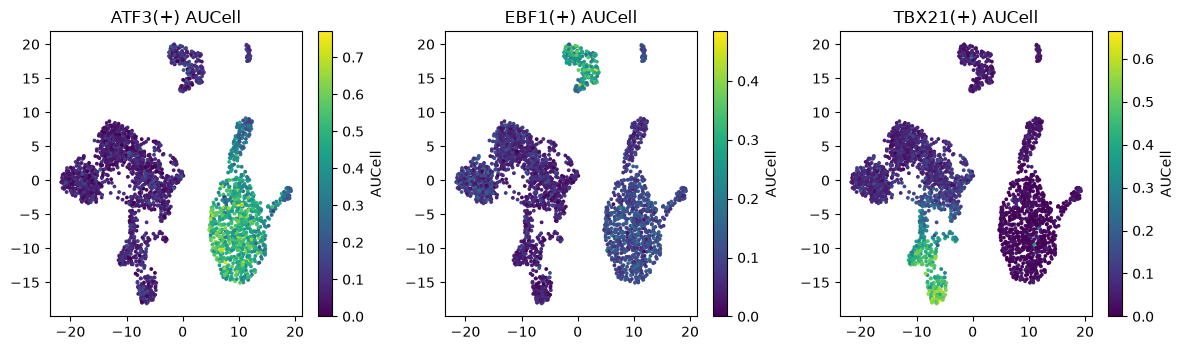

Started: 2026-10-16T09:20:09.472122Z | Wall time: 0.594 s

In [7]:
# Read the UMAP coordinates of the analysed cells.
umap = run.cells.to_pandas_dataframe(["umap_1", "umap_2"])

# Pick the most specific regulon of three lineages.
shown = rss.loc[["CD14 monocyte", "B cell", "NK cell"]].idxmax(axis=1).unique()

# Create one panel per regulon.
figure, axes = plt.subplots(1, len(shown), figsize=(4 * len(shown), 3.6))

# Color the cells of each panel by one regulon's activity.
for axis, name in zip(axes, shown, strict=True):

    # Plot every analysed cell at its UMAP position.
    points = axis.scatter(umap["umap_1"], umap["umap_2"], c=activity[name], s=3)

    # Name the regulon shown in the panel.
    axis.set_title(f"{name} AUCell")

    # Label the activity scale.
    figure.colorbar(points, ax=axis, label="AUCell")

# Make room for the panel titles and color scales.
figure.tight_layout()

# Display the regulon maps.
plt.show()

The most specific regulons are known lineage factors: TBX21 and EOMES in NK cells, EBF1 in
B cells, CEBPA and CEBPB in CD16 monocytes, and ETS1 and BACH2 in CD4 T cells.

Regulons that are active in the same cells may act together. The connection specificity
index (CSI) of two regulons is the fraction of all regulons that correlate less with both of
them than they do with each other. Clustering the CSI groups the regulons into modules, as
SCENIC analyses do.

In [8]:
# Score how specifically each pair of regulons is active in the same cells.
csi = rg.connection_specificity(activity)

# Group the regulons into five co-activity modules.
regulon_groups = rg.regulon_modules(csi, n_modules=5)

# Average the activity of each module's regulons, then within each population.
module_activity = activity.T.groupby(regulon_groups).mean().T.groupby(cell_type).mean()

# List the regulons of each module and the population where the module is most active.
pd.DataFrame({
    "regulons": regulon_groups.groupby(regulon_groups).apply(lambda group: ", ".join(group.index[:8])),
    "most active in": module_activity.idxmax(),
})

,regulons,most active in
module,,
1,"ATF3(+), BACH1(+), BATF3(+), BCL6(+), CEBPA(+), CEBPB(+), CEBPD(+), CHD1(+)",CD14 monocyte
2,"ARID3A(+), ATF5(+), CHURC1(+), CLOCK(+), CTBP1(+), EBF1(+), ELK1(+), ETV3(+)",Plasmacytoid DC
3,"BACH2(+), BHLHE40(+), BPTF(+), EOMES(+), ETS1(+), HDAC1(+), IKZF2(+), IKZF3(+)",CD8 T cell
4,"CTCF(+), EGR3(+), ELF4(+), FOXJ2(+), GMEB2(+), MAFF(+), MAFK(+), MAX(+)",CD14 monocyte
5,"BCLAF1(+), ELF1(+), ELK3(+), ETV7(+), NFE2L2(+), NRF1(+), TAF6(+), ZBTB11(+)",NK cell


Started: 2026-10-16T09:20:10.068575Z | Wall time: 0.103 s

## Find co-regulated gene programs

A regulon starts from a known factor. A gene program starts from the genes: genes that rise
and fall together across many groups of similar cells are likely regulated as a unit, whether
or not we know the factor. This needs only RNA, so it applies to any scRNA-seq dataset.

Pool the analysed cells into about a hundred small groups (metacells) to average out
sampling noise; `ds.regulons.profiles` sums each metacell's counts into log counts per million,
for RNA and for ATAC. Then connect each variable gene to the genes it correlates with most across
metacells and split that graph into programs with Leiden.

In [9]:
# Group the analysed cells into small, similar groups (metacells) with a fine Leiden partition.
metacells = ds.clusters.leiden(run["connectivity_map"], resolution=15)

# Sum the RNA and ATAC counts of each metacell as log counts per million.
profiles = {assay: ds.regulons.profiles(metacells, from_assay=assay) for assay in ("RNA", "ATAC")}

# Keep the variable genes that name a single feature of the profiles.
program_genes = [gene for gene in names[variable] if gene in profiles["RNA"].columns]

# Split the variable genes into programs of co-varying genes.
programs = rg.gene_programs(profiles["RNA"][program_genes])

# List the size and the eight most typical genes of each program.
programs.groupby("source", sort=False)["target"].agg(
    size="size",
    leading_genes=lambda genes: ", ".join(genes.head(8)),
)

,size,leading_genes
source,,
P1,212,"ABLIM1, BCL11B, CAMK4, LEF1, TC2N, RASGRF2, ZEB1, IL7R"
P2,210,"RIN2, GLT1D1, CLEC7A, PLXDC2, SLC24A4, WDFY3, VCAN-AS1, KLF4"
P3,126,"LINC02397, CD19, KLHL14, FCRL2, PAX5, FCRLA, IGHD, FCRL5"
P4,98,"PTGDR, PPP2R2B, CST7, XCL2, PDGFD, LGR6, S1PR5, FCRL6"
P5,80,"MEF2C, SYK, KYNU, TBC1D9, WDFY4, ARHGAP24, CD74, IRF8"
P6,23,"LINC01478, LRRC26, P3H2, PHEX, TNFRSF21, CLEC4C, SCAMP5, DNASE1L3"


Started: 2026-10-16T09:20:10.174422Z | Wall time: 41.989 s

Each program lists its genes by `membership`, the correlation of a gene with the program's
average profile, so the leading genes are the most typical. They already suggest identities:
T-cell genes in P1 (BCL11B, LEF1, IL7R), monocyte genes in P2 (CLEC7A, KLF4), B-cell genes in
P3 (CD19, PAX5), cytotoxic genes in P4 (CST7, XCL2), antigen-presentation genes in P5 (CD74,
IRF8), and plasmacytoid DC genes in P6 (CLEC4C, LRRC26). Score each program in every
cell with AUCell, as for the regulons.

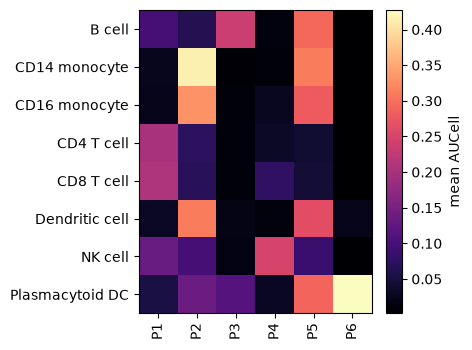

Started: 2026-10-16T09:20:52.166418Z | Wall time: 0.936 s

In [10]:
# Draw a table of population averages as a labelled heatmap.
def heatmap(table, label, **colors):

    # Widen the figure with the number of columns.
    figure, axis = plt.subplots(figsize=(0.45 * table.shape[1] + 2, 3.6))

    # Color every value of the table.
    image = axis.imshow(table.to_numpy(), aspect="auto", **colors)

    # Label the columns.
    axis.set_xticks(range(table.shape[1]), table.columns, rotation=90)

    # Label the rows.
    axis.set_yticks(range(table.shape[0]), table.index)

    # Label the color scale.
    figure.colorbar(image, ax=axis, label=label)

    # Fit the labels into the figure.
    figure.tight_layout()

    # Display the heatmap.
    plt.show()


# Score each program in every analysed cell.
program_auc = ds.scores.aucell(programs, cells, features=run["feature_universe"], tmin=10)

# Average each program's activity within each population.
program_means = ds.scores.load(program_auc).to_pandas().groupby(cell_type).mean()

# Show the averages as a heatmap.
heatmap(program_means, "mean AUCell", cmap="magma")

Each program is most active where its genes suggest: P2 in monocytes and dendritic cells, P3
in B cells, P4 in NK cells, and P6 in plasmacytoid DCs, while P1 marks T cells and P5 the
antigen-presenting B cells, monocytes, and both kinds of dendritic cells.

Which factors might drive a program? The programs were found without any factor, so compare
them with the regulons: a program that shares many genes with a regulon is a candidate unit
of that factor. The test counts shared genes among the variable genes that both could
contain.

In [11]:
# Test every program for overlap with every regulon among the variable genes.
overlaps = rg.set_overlaps(programs, regulons, program_genes)

# Keep the three most significant overlapping regulons of each program.
shared = overlaps[overlaps["q_value"] < 0.05].sort_values("p_value").groupby("query").head(3)

# List them by program.
shared.groupby("query")["reference"].agg(", ".join).to_frame("overlapping regulons")

,overlapping regulons
query,
P1,"ETS1(+), KLF12(+), IKZF3(+)"
P2,"KLF4(+), KLF6(+), BACH1(+)"
P3,"TCF4(+), IKZF3(+)"
P4,"TBX21(+), IKZF2(+), EOMES(+)"
P5,"TCF4(+), BACH1(+), KLF4(+)"
P6,"TCF3(+), ARID3A(+)"


Started: 2026-10-16T09:20:53.104723Z | Wall time: 0.113 s

The overlaps tie programs to lineage factors: the T-cell program to ETS1, the monocyte
program to KLF4, the NK program to TBX21 and EOMES, and the B-cell program to TCF4 and
IKZF3.

A second route needs no regulons: test each program's own genes for motif enrichment with the
database that pruned the regulons. Large programs enrich many weak motifs, so keep the factors
whose own expression follows the program across metacells. Both routes nominate candidates
to test, not demonstrated regulators.

In [12]:
# Find motifs that rank each program's genes highly, and correlate each nominated
# factor's expression with its program across metacells.
program_tfs = rg.program_regulators(programs, database, annotations, profiles=profiles["RNA"])

# Keep the strongest motif of each factor in each program; rows are sorted by NES.
program_tfs = program_tfs.drop_duplicates(["program", "TF"])

# Keep the factors whose expression follows their program closely.
supported = program_tfs[program_tfs["correlation"] > 0.6]

# Rank the factors of each program by correlation.
supported = supported.sort_values(["program", "correlation"], ascending=[True, False])

# List the three best-correlated factors of each program.
supported.groupby("program").head(3)[["program", "TF", "motif", "NES", "correlation"]]

,program,TF,motif,NES,correlation
52,P1,ETS1,tfdimers__MD00364,3.280418,0.916811
205,P1,IKZF3,metacluster_133.2,3.139664,0.850138
208,P1,KLF12,metacluster_133.2,3.139664,0.772299
476,P3,EBF1,transfac_pro__M04924,3.047011,0.901221
500,P4,GFI1,tfdimers__MD00030,3.201721,0.683839
1144,P5,TCF4,tfdimers__MD00164,3.076386,0.884050
745,P5,PLAGL1,metacluster_133.2,3.287523,0.825758
887,P5,SPI1,metacluster_24.2,3.257480,0.794866


Started: 2026-10-16T09:20:53.219798Z | Wall time: 1.544 s

Four of the six programs have an enriched motif whose factor follows them closely. The factors
agree with the overlaps for the T-cell program (ETS1, IKZF3, and KLF12) and the
antigen-presentation program (TCF4), while the motifs name EBF1 for the B-cell program, which
its overlaps miss. A shared regulon is stronger evidence than motif enrichment of a large program.

## Score motif accessibility in the same cells

chromVAR asks whether a cell has more ATAC fragments in the peaks that hold a motif than its
sequencing depth and those peaks' average accessibility predict. It compares each motif's peaks
with background peaks of similar GC content and accessibility. First find the peaks that
contain each motif, and assign them to the factor that the motif is named after. To keep this page short, scan the JASPAR motifs of a panel of immune
factors; scan the whole collection for discovery.

In [13]:
# Use every peak with a fragment among the analysed cells.
peaks = ds.features.detected(cells, from_assay="ATAC", min_cells=1)

# Mark those peaks.
selected = np.asarray(ds.artifacts.load(peaks)["values"][:], dtype=bool)

# Read their ids, which give their coordinates as chrom:start-end.
peak_ids = np.asarray(ds.ATAC.feats.fetch_all("ids")).astype(str)[selected]

# Name factors whose motifs mark PBMC populations.
panel = ["SPI1", "CEBPA", "CEBPB", "IRF8", "KLF4", "PAX5", "EBF1", "POU2F2", "TBX21",
         "EOMES", "RUNX3", "GATA3", "TCF7", "LEF1", "CTCF", "IRF4", "MEF2C", "NFKB1"]

# Index the JASPAR motifs by factor name, keeping each factor's first motif.
first_motif = {}
for motif in rg.read_jaspar_motifs(jaspar):
    first_motif.setdefault(motif.name.upper(), motif)

# Scan the first motif of each panel factor that JASPAR holds.
motifs = [first_motif[name] for name in panel if name in first_motif]

# Find the peaks that hold a match of each motif on either strand.
with rg.IndexedFasta(genome_fa) as genome:
    matches = rg.match_motifs(peak_ids, genome, motifs)

# Assign each motif's peaks to the factor that the motif is named after.
cistromes = rg.cistromes_from_motifs(matches, rg.motif_annotations(motifs))

# Count the matching peaks of each factor.
cistromes["source"].value_counts().to_frame("peaks with a match").T

source,SPI1,KLF4,CTCF,MEF2C,EBF1,RUNX3,IRF8,CEBPA,POU2F2,EOMES,NFKB1,IRF4,TCF7,GATA3,TBX21,LEF1,CEBPB,PAX5
peaks with a match,43155,31982,28507,26353,17695,13727,12806,12461,12395,11427,11343,11162,10664,9868,8928,8819,3293,3108


Started: 2026-10-16T09:20:54.765962Z | Wall time: 30.210 s

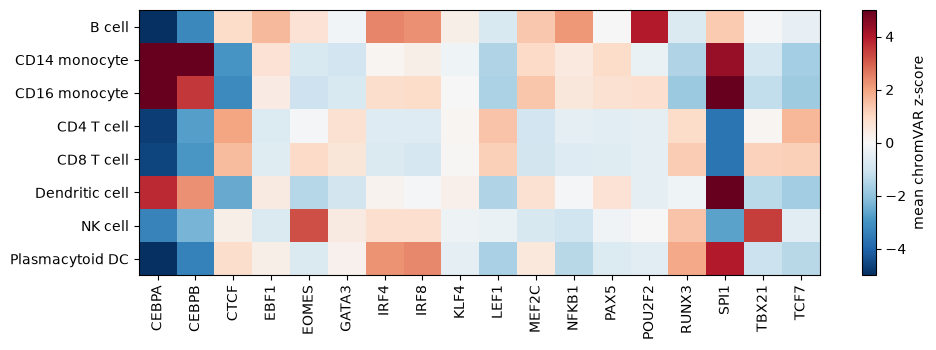

Started: 2026-10-16T09:21:24.978118Z | Wall time: 32.032 s

In [14]:
# Score the accessibility of each factor's motif peaks in every analysed cell.
motif_activity = ds.scores.chromvar(
    cistromes,
    cells,
    from_assay="ATAC",
    features=peaks,
    genome=genome_fa,
)

# Average each factor's z-scores within each population.
motif_means = ds.scores.load(motif_activity).to_pandas().groupby(cell_type).mean()

# Show the averages as a heatmap centred on zero.
heatmap(motif_means, "mean chromVAR z-score", cmap="RdBu_r", vmin=-5, vmax=5)

Motif accessibility agrees with the RNA regulons. The CEBPA and CEBPB motifs are most
accessible in monocytes; SPI1 (PU.1) in monocytes and dendritic cells; POU2F2 in B cells;
IRF4 and IRF8 in B cells and plasmacytoid DCs; TBX21 and EOMES in NK cells; and TCF7 and LEF1
in T cells.
Related factors share motifs, so each column measures a motif family rather than one factor.
The PAX5 motif does not separate B cells here and the EBF1 motif does so only weakly, so a
missing deviation is not evidence that a factor is inactive.

## Score CUT&RUN binding sites

A CUT&RUN experiment for one factor maps where that factor was bound, without relying on a
motif. Map the SPI1 (PU.1) peaks from primary monocytes onto the ATAC peaks and score them in
the same way. Any set of regions works: CUT&Tag or ChIP-seq peaks, or peaks of another
dataset.

In [15]:
# Map the SPI1 CUT&RUN peaks onto the ATAC peaks.
binding = rg.binding_cistromes({"SPI1": spi1_cutrun}, peak_ids)

# Count the ATAC peaks that SPI1 binds.
print(f"{len(binding):,} ATAC peaks overlap an SPI1 CUT&RUN peak")

# Score the accessibility of the bound peaks in every analysed cell.
bound_activity = ds.scores.chromvar(
    binding,
    cells,
    from_assay="ATAC",
    features=peaks,
    genome=genome_fa,
)

# Read the z-scores of the bound peaks.
bound_z = ds.scores.load(bound_activity).to_pandas()["SPI1"]

# Compare the mean z-scores of the bound peaks and of the SPI1 motif in each population.
pd.DataFrame({
    "SPI1 CUT&RUN peaks": bound_z.groupby(cell_type).mean(),
    "SPI1 motif": motif_means["SPI1"],
}).round(2)

2,519 ATAC peaks overlap an SPI1 CUT&RUN peak


,SPI1 CUT&RUN peaks,SPI1 motif
B cell,-1.34,1.30
CD14 monocyte,10.69,4.36
CD16 monocyte,10.75,5.69
CD4 T cell,-6.87,-3.65
CD8 T cell,-6.83,-3.67
Dendritic cell,11.32,7.15
NK cell,-4.64,-2.68
Plasmacytoid DC,0.32,3.97


Started: 2026-10-16T09:21:57.012559Z | Wall time: 27.833 s

The sites that SPI1 occupies in monocytes separate myeloid cells from lymphocytes more sharply
than its motif does, because the motif also counts sites that the factor does not use. B cells
and plasmacytoid DCs, where the motif is moderately accessible, show no enrichment of these
monocyte sites: binding sites differ between cell types even for one factor.

## Build enhancer-driven regulons

With RNA and ATAC from the same cells, we can ask which peaks near a gene track its
expression. SCENIC+ links each peak within 150 kb of a gene body to that gene by a
gradient-boosting importance and a rank correlation across metacells. A factor's
**eRegulon** keeps its links whose peaks hold its motif (or its binding sites) and whose
genes rank high in the factor's GRNBoost2 network, tested by preranked GSEA.

In [16]:
# Read the protein-coding genes of the annotation.
genes_table = rg.read_gene_annotation(gene_gtf, gene_types={"protein_coding"})

# Pair each peak with the genes whose body lies within 150 kb of it.
candidates = rg.link_regions_to_genes(
    peak_ids,
    genes_table,
    upstream=150_000,
    downstream=150_000,
    anchor="gene_body",
)

# Keep the candidate links of genes that the co-expression network models.
candidates = candidates[candidates["gene"].isin(adjacencies["target"])]

# Score every candidate link across metacells.
links = rg.region_gene_links(profiles["ATAC"], profiles["RNA"], candidates, nthreads=4)

# Build eRegulons from the motif cistromes and from the SPI1 CUT&RUN peaks.
eregulons = pd.concat([
    rg.build_eregulons(cistromes, links, adjacencies, nthreads=4),
    rg.build_eregulons(binding, links, adjacencies, label="CUTRUN", nthreads=4),
])

# Count the peaks and genes of each eRegulon.
sizes = eregulons.groupby("source").agg(peaks=("region", "nunique"), genes=("target", "nunique"))

# List the activator eRegulons.
sizes.filter(like="+/+", axis=0)

,peaks,genes
source,,
CEBPA_direct_+/+,141,64
CEBPB_direct_+/+,36,32
CTCF_direct_+/+,221,83
EBF1_direct_+/+,182,67
EOMES_direct_+/+,44,22
GATA3_direct_+/+,68,35
IRF4_direct_+/+,90,44
IRF8_direct_+/+,222,100
KLF4_direct_+/+,606,154


Started: 2026-10-16T09:22:24.847892Z | Wall time: 667.507 s

An eRegulon name gives its factor, the evidence for binding (`direct` motif annotation or
`CUTRUN` peaks), and two signs: whether the factor's expression rises (`+`) or falls (`-`)
with its target genes, and whether the linked peaks open (`+`) or close (`-`) with them. The
table lists the `+/+` eRegulons, activators whose target peaks open with the targets; the
other sign classes are kept in `eregulons`. Each row also carries the `NES` and `adjusted_p` of
the module that kept it; SCENIC+'s defaults keep every module with a positive NES, so filter on
`adjusted_p` for stricter eRegulons. Score the target genes of each eRegulon as before.

In [17]:
# Score the target genes of every eRegulon in every analysed cell; a gene linked by
# several peaks counts once.
eregulon_auc = ds.scores.aucell(
    eregulons[["source", "target"]].drop_duplicates(),
    cells,
    features=run["feature_universe"],
    tmin=10,
)

# Average each activator eRegulon's activity within each population.
eregulon_means = ds.scores.load(eregulon_auc).to_pandas().filter(like="+/+").groupby(cell_type).mean()

# Name the population where each activator eRegulon is most active.
pd.DataFrame({"most active in": eregulon_means.idxmax(), "mean AUCell": eregulon_means.max().round(3)})

,most active in,mean AUCell
CEBPA_direct_+/+,CD16 monocyte,0.523
CEBPB_direct_+/+,CD16 monocyte,0.660
CTCF_direct_+/+,NK cell,0.205
EBF1_direct_+/+,B cell,0.457
EOMES_direct_+/+,NK cell,0.452
GATA3_direct_+/+,NK cell,0.293
IRF4_direct_+/+,Plasmacytoid DC,0.634
IRF8_direct_+/+,Plasmacytoid DC,0.524
KLF4_direct_+/+,CD14 monocyte,0.584
LEF1_direct_+/+,CD4 T cell,0.444


Started: 2026-10-16T09:33:32.357471Z | Wall time: 0.993 s

The activator eRegulons of lineage factors are most active where expected: the CEBP, SPI1,
and KLF4 eRegulons in monocytes, EBF1 and PAX5 in B cells, EOMES, TBX21, and RUNX3 in NK cells,
IRF4 and IRF8 in plasmacytoid DCs, and LEF1 and TCF7 in CD4 T cells. The SPI1 eRegulon built
from CUT&RUN peaks agrees with the one built from motifs.

## What to report

- Regulons, programs, and eRegulons are hypotheses. GRNBoost2 is stochastic: rerun
  `ds.regulons.grn` with another `random_seed` and report the regulons that persist.
- Use reference files that match the data: the genome build and gene annotation of the peaks,
  and a cisTarget database for the same species and gene names.
- A motif is shared by related factors, so a motif score names a family; pair it with the
  factor's expression or binding data before naming the factor.
- Binding data describe the cells that were profiled; the SPI1 peaks here come from
  monocytes.

[The methods page](../reference/methods.md) summarizes how these methods were validated
against pySCENIC 0.12.1 and chromVAR, and the [regulons API reference](/api/regulons.html)
lists every function.